In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("Stock_Prices.csv")

df.head()

,Date,AAPL,MSFT,GOOGL,AMZN,TSLA
0,2025-01-01,243.85,418.60,190.20,220.10,379.2
1,2025-01-02,245.10,420.25,191.75,221.80,385.6
2,2025-01-03,244.30,417.90,189.90,219.75,372.8
3,2025-01-04,246.75,422.10,193.10,223.40,390.1
4,2025-01-05,248.20,424.80,194.85,225.20,398.5


In [3]:
print("Dataset Shape:", df.shape)

Dataset Shape: (30, 6)


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    30 non-null     str    
 1   AAPL    30 non-null     float64
 2   MSFT    30 non-null     float64
 3   GOOGL   30 non-null     float64
 4   AMZN    30 non-null     float64
 5   TSLA    30 non-null     float64
dtypes: float64(5), str(1)
memory usage: 1.8 KB


In [5]:
df.describe()

,AAPL,MSFT,GOOGL,AMZN,TSLA
count,30.000000,30.000000,30.000000,30.000000,30.000000
mean,254.405000,435.248333,201.721667,234.273333,440.765000
std,6.057019,10.023012,6.810333,8.551031,42.516472
min,243.850000,417.900000,189.900000,219.750000,372.800000
25%,249.462500,426.837500,196.150000,227.137500,404.500000
50%,254.675000,435.750000,202.100000,234.650000,440.200000
75%,259.150000,443.350000,207.200000,241.175000,476.400000
max,264.500000,451.600000,212.800000,248.300000,516.800000


In [6]:
df.columns

Index(['Date', 'AAPL', 'MSFT', 'GOOGL', 'AMZN', 'TSLA'], dtype='str')

In [7]:
df["Date"] = pd.to_datetime(df["Date"])

df.head()

,Date,AAPL,MSFT,GOOGL,AMZN,TSLA
0,2025-01-01,243.85,418.60,190.20,220.10,379.2
1,2025-01-02,245.10,420.25,191.75,221.80,385.6
2,2025-01-03,244.30,417.90,189.90,219.75,372.8
3,2025-01-04,246.75,422.10,193.10,223.40,390.1
4,2025-01-05,248.20,424.80,194.85,225.20,398.5


In [8]:
df = df.sort_values("Date")

In [9]:
df.set_index("Date", inplace=True)

df.head()

,AAPL,MSFT,GOOGL,AMZN,TSLA
Date,,,,,
2025-01-01,243.85,418.60,190.20,220.10,379.2
2025-01-02,245.10,420.25,191.75,221.80,385.6
2025-01-03,244.30,417.90,189.90,219.75,372.8
2025-01-04,246.75,422.10,193.10,223.40,390.1
2025-01-05,248.20,424.80,194.85,225.20,398.5


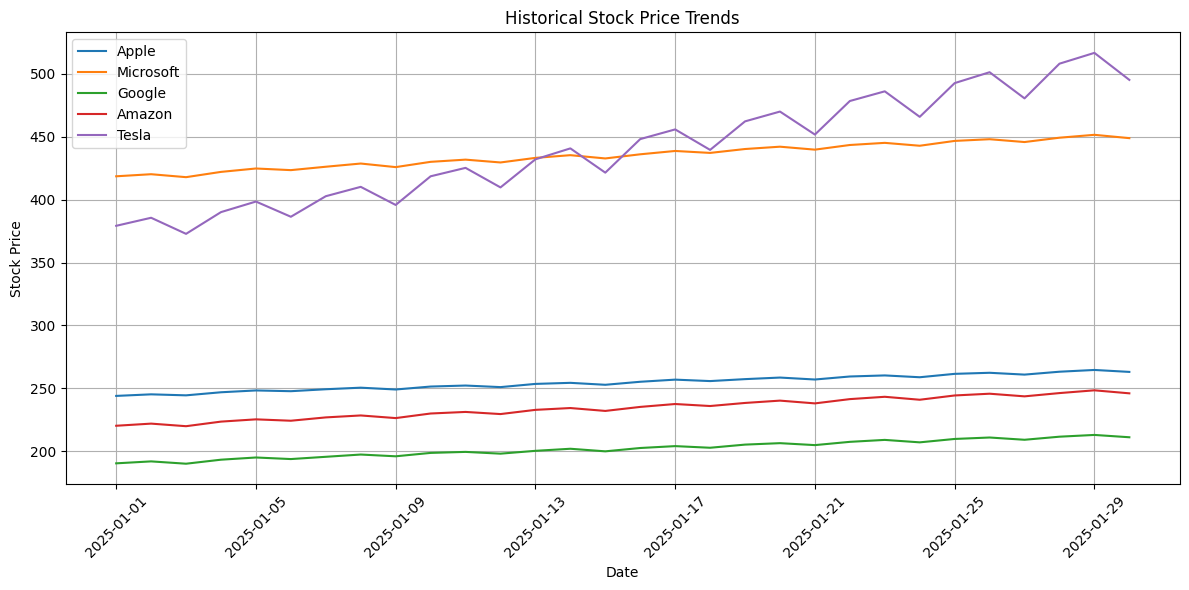

In [10]:
plt.figure(figsize=(12, 6))

plt.plot(df.index, df["AAPL"], label="Apple")
plt.plot(df.index, df["MSFT"], label="Microsoft")
plt.plot(df.index, df["GOOGL"], label="Google")
plt.plot(df.index, df["AMZN"], label="Amazon")
plt.plot(df.index, df["TSLA"], label="Tesla")

plt.title("Historical Stock Price Trends")
plt.xlabel("Date")
plt.ylabel("Stock Price")

plt.legend()
plt.grid(True)

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [11]:
df["AAPL_MA5"] = df["AAPL"].rolling(window=5).mean()

df[["AAPL", "AAPL_MA5"]].head(10)

,AAPL,AAPL_MA5
Date,,
2025-01-01,243.85,NaN
2025-01-02,245.10,NaN
2025-01-03,244.30,NaN
2025-01-04,246.75,NaN
2025-01-05,248.20,245.64
2025-01-06,247.60,246.39
2025-01-07,249.15,247.20
2025-01-08,250.40,248.42
2025-01-09,248.95,248.86


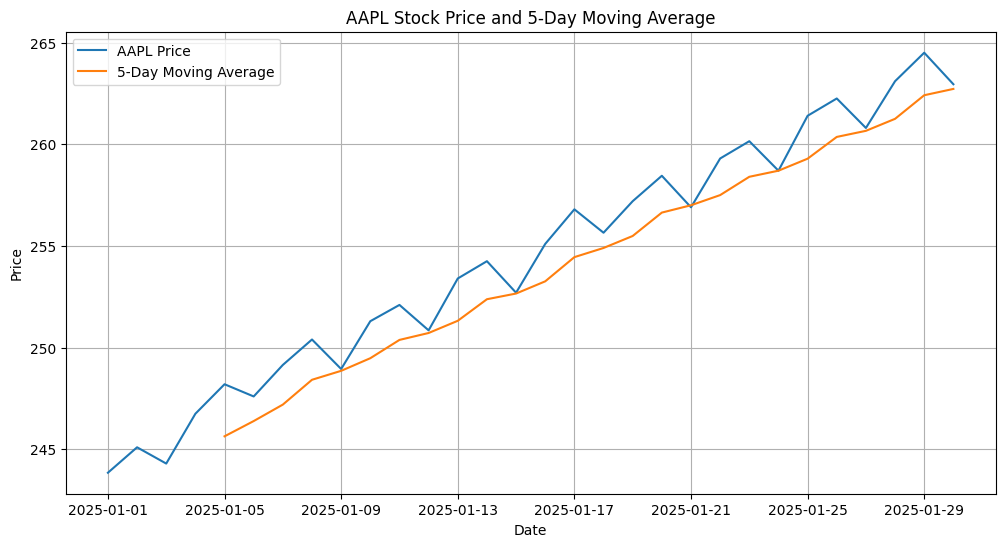

In [12]:
plt.figure(figsize=(12, 6))

plt.plot(
    df.index,
    df["AAPL"],
    label="AAPL Price"
)

plt.plot(
    df.index,
    df["AAPL_MA5"],
    label="5-Day Moving Average"
)

plt.title("AAPL Stock Price and 5-Day Moving Average")
plt.xlabel("Date")
plt.ylabel("Price")

plt.legend()
plt.grid(True)

plt.show()

In [13]:
companies = ["AAPL", "MSFT", "GOOGL", "AMZN", "TSLA"]

for company in companies:
    df[company + "_MA5"] = df[company].rolling(window=5).mean()

df.head()

,AAPL,MSFT,GOOGL,AMZN,TSLA,AAPL_MA5,MSFT_MA5,GOOGL_MA5,AMZN_MA5,TSLA_MA5
Date,,,,,,,,,,
2025-01-01,243.85,418.60,190.20,220.10,379.2,NaN,NaN,NaN,NaN,NaN
2025-01-02,245.10,420.25,191.75,221.80,385.6,NaN,NaN,NaN,NaN,NaN
2025-01-03,244.30,417.90,189.90,219.75,372.8,NaN,NaN,NaN,NaN,NaN
2025-01-04,246.75,422.10,193.10,223.40,390.1,NaN,NaN,NaN,NaN,NaN
2025-01-05,248.20,424.80,194.85,225.20,398.5,245.64,420.73,191.96,222.05,385.24


In [14]:
returns = df[companies].pct_change() * 100

returns.head()

,AAPL,MSFT,GOOGL,AMZN,TSLA
Date,,,,,
2025-01-01,NaN,NaN,NaN,NaN,NaN
2025-01-02,0.512610,0.394171,0.814932,0.772376,1.687764
2025-01-03,-0.326397,-0.559191,-0.964798,-0.924256,-3.319502
2025-01-04,1.002865,1.005025,1.685097,1.660978,4.640558
2025-01-05,0.587639,0.639659,0.906266,0.805730,2.153294


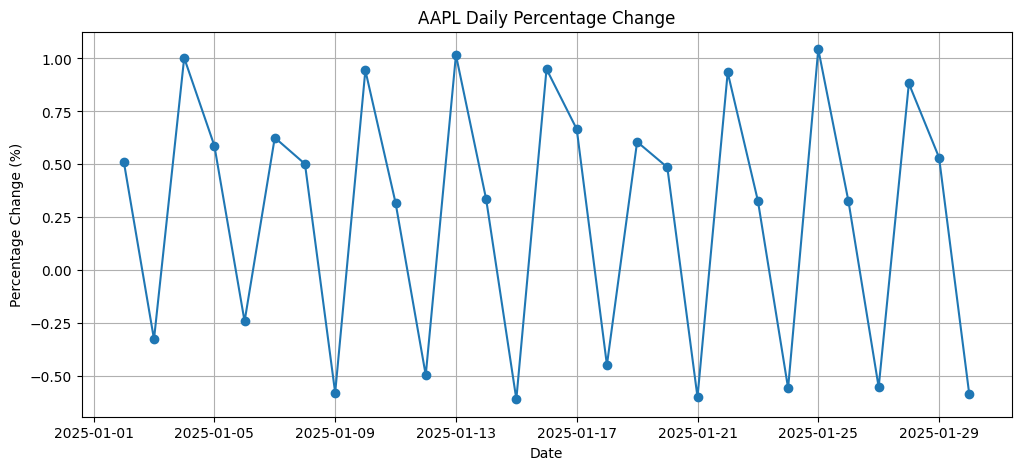

In [15]:
plt.figure(figsize=(12, 5))

plt.plot(
    returns.index,
    returns["AAPL"],
    marker="o"
)

plt.title("AAPL Daily Percentage Change")
plt.xlabel("Date")
plt.ylabel("Percentage Change (%)")

plt.grid(True)

plt.show()

In [16]:
correlation = df[companies].corr()

correlation

,AAPL,MSFT,GOOGL,AMZN,TSLA
AAPL,1.000000,0.999262,0.998924,0.999221,0.991907
MSFT,0.999262,1.000000,0.999530,0.999668,0.991987
GOOGL,0.998924,0.999530,1.000000,0.999515,0.993049
AMZN,0.999221,0.999668,0.999515,1.000000,0.993363
TSLA,0.991907,0.991987,0.993049,0.993363,1.000000


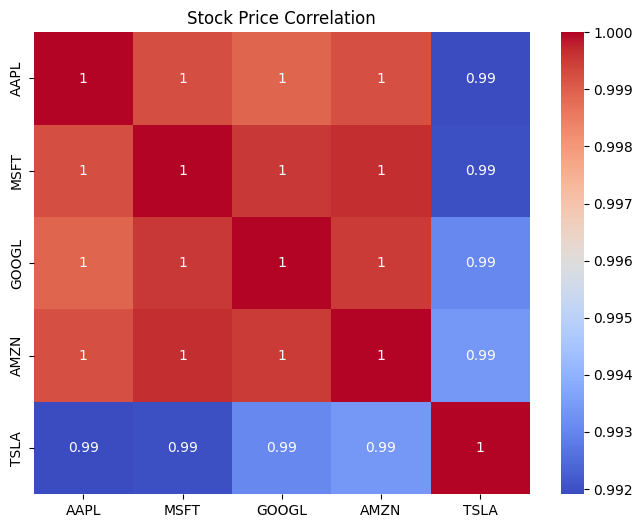

In [17]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm"
)

plt.title("Stock Price Correlation")

plt.show()

In [18]:
from statsmodels.tsa.arima.model import ARIMA

In [19]:
pip install statsmodels

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [20]:
aapl = df["AAPL"].dropna()

aapl.head()

Date
2025-01-01    243.85
2025-01-02    245.10
2025-01-03    244.30
2025-01-04    246.75
2025-01-05    248.20
Name: AAPL, dtype: float64

In [21]:
train_size = int(len(aapl) * 0.8)

train = aapl[:train_size]
test = aapl[train_size:]

print("Training records:", len(train))
print("Testing records:", len(test))

Training records: 24
Testing records: 6


In [22]:
model = ARIMA(
    train,
    order=(1, 1, 1)
)

model_fit = model.fit()

print(model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                   AAPL   No. Observations:                   24
Model:                 ARIMA(1, 1, 1)   Log Likelihood                 -42.880
Date:                Wed, 07 Oct 2026   AIC                             91.760
Time:                        20:18:21   BIC                             95.167
Sample:                    01-01-2025   HQIC                            92.617
                         - 01-24-2025                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.1018      1.330     -0.077      0.939      -2.708       2.505
ma.L1         -0.1283      1.467     -0.087      0.930      -3.003       2.747
sigma2         2.4315      1.946      1.249      0.2

c:\Users\asjun\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\asjun\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\asjun\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\asjun\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\asjun\AppData\Local\Pr

In [23]:
forecast = model_fit.forecast(
    steps=len(test)
)

forecast

2025-01-25    259.000073
2025-01-26    258.969528
2025-01-27    258.972638
2025-01-28    258.972321
2025-01-29    258.972353
2025-01-30    258.972350
Freq: D, Name: predicted_mean, dtype: float64

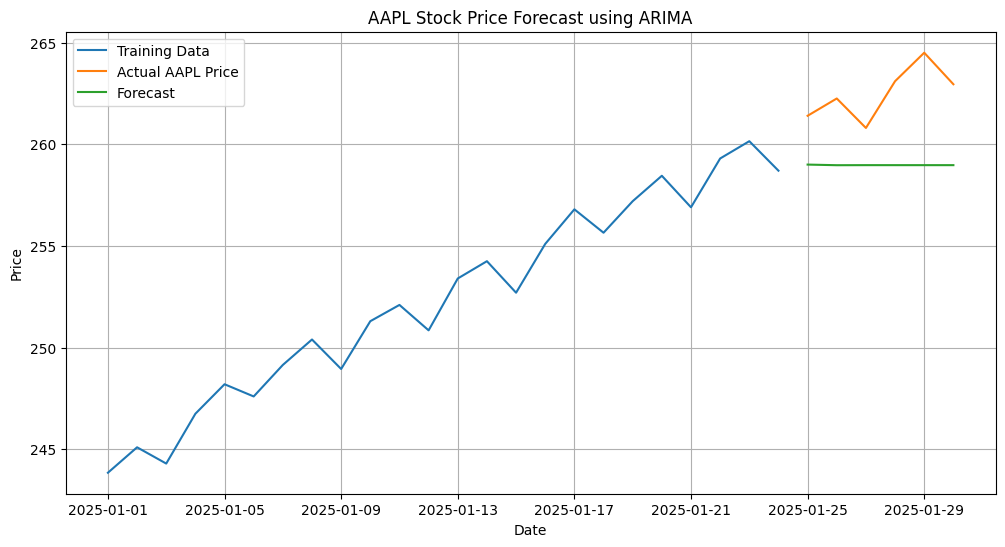

In [24]:
plt.figure(figsize=(12, 6))

plt.plot(
    train.index,
    train,
    label="Training Data"
)

plt.plot(
    test.index,
    test,
    label="Actual AAPL Price"
)

plt.plot(
    test.index,
    forecast,
    label="Forecast"
)

plt.title("AAPL Stock Price Forecast using ARIMA")
plt.xlabel("Date")
plt.ylabel("Price")

plt.legend()
plt.grid(True)

plt.show()

In [25]:
df["AAPL"]
df["MSFT"]
df["GOOGL"]
df["AMZN"]
df["TSLA"]

Date
2025-01-01    379.20
2025-01-02    385.60
2025-01-03    372.80
2025-01-04    390.10
2025-01-05    398.50
2025-01-06    386.40
2025-01-07    402.75
2025-01-08    410.20
2025-01-09    395.80
2025-01-10    418.60
2025-01-11    425.30
2025-01-12    409.75
2025-01-13    432.10
2025-01-14    440.80
2025-01-15    421.50
2025-01-16    448.20
2025-01-17    455.90
2025-01-18    439.60
2025-01-19    462.30
2025-01-20    470.10
2025-01-21    451.80
2025-01-22    478.50
2025-01-23    486.20
2025-01-24    465.90
2025-01-25    492.75
2025-01-26    501.40
2025-01-27    480.60
2025-01-28    508.20
2025-01-29    516.80
2025-01-30    495.30
Name: TSLA, dtype: float64